#  Extension de l'architecture 

## 1. Imports et configuration

In [ ]:
import os, time, random, copy, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

from charte_graphique import appliquer_charte, BLEU, ROUGE, BLANC, GRIS, teintes
appliquer_charte()
warnings.filterwarnings("ignore")

GRIS_LIGNE = "#8A8A8A"      

def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed(0)
torch.set_num_threads(1)      
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device, "| torch", torch.__version__)

Device : cpu | torch 2.15.0+cpu


## Load data & DataLoaders

In [2]:
DATA_DIR = os.environ.get("HAR_DIR", "../data/processed_har_data")

train_df = pd.read_csv(f"{DATA_DIR}/train_processed.csv")
val_df   = pd.read_csv(f"{DATA_DIR}/val_processed.csv")    

feature_cols = [c for c in train_df.columns if c not in ("subject", "Activity")]
classes = sorted(train_df["Activity"].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}
n_classes = len(classes)

X_train_s = train_df[feature_cols].to_numpy(dtype=np.float32)
y_train   = train_df["Activity"].map(class_to_idx).to_numpy(dtype=np.int64)
X_val_s   = val_df[feature_cols].to_numpy(dtype=np.float32)
y_val     = val_df["Activity"].map(class_to_idx).to_numpy(dtype=np.int64)
in_dim = X_train_s.shape[1]

print("X_train_s :", X_train_s.shape, "| X_val_s :", X_val_s.shape, "| classes :", n_classes)

def make_loader(X, y, batch_size=128, shuffle=False, seed=0):
    g = torch.Generator(); g.manual_seed(seed)
    ds = TensorDataset(torch.from_numpy(X), torch.from_numpy(y))
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, generator=g if shuffle else None)

val_loader = make_loader(X_val_s, y_val, 512)

X_train_s : (5657, 561) | X_val_s : (1695, 561) | classes : 6


In [ ]:
# Ref : régression logistique 
logreg = LogisticRegression(max_iter=500).fit(X_train_s, y_train)
pred_lr = logreg.predict(X_val_s)
ref_acc = accuracy_score(y_val, pred_lr)
ref_f1  = f1_score(y_val, pred_lr, average="macro")
print(f"Régression logistique (validation) : accuracy = {ref_acc:.4f} | F1 macro = {ref_f1:.4f}")

Régression logistique (validation) : accuracy = 0.9168 | F1 macro = 0.9187


## MLP à nombre de couches et d'activations variables


In [ ]:
ACTIVATIONS = {"relu": nn.ReLU, "tanh": nn.Tanh, "sigmoid": nn.Sigmoid}

class MLP(nn.Module):
    
    def __init__(self, in_dim, hidden=(64,), n_classes=6, act="relu"):
        super().__init__()
        acts = [act] * len(hidden) if isinstance(act, str) else list(act)
        assert len(acts) == len(hidden), "vérfie qu'on a bien une activation par couche cachée"
        layers, d = [], in_dim
        for h, a in zip(hidden, acts):
            layers += [nn.Linear(d, h), ACTIVATIONS[a]()]
            d = h
        self.features = nn.Sequential(*layers)    #hidden part of the mlp : on enchaine tous ces couches en ordre 
        self.out_layer = nn.Linear(d, n_classes)  #d=64 taille de sortie de la derniere hidden layer

    def forward(self, x):
        return self.out_layer(self.features(x))

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

# nombre de paramètres selon l'architecture
for h in [(64,), (128,), (64, 64), (64, 64, 64)]:
    print(f"hidden = {str(h):<16} -> {count_params(MLP(in_dim, h, n_classes)):>7} paramètres")

hidden = (64,)            ->   36358 paramètres
hidden = (128,)           ->   72710 paramètres
hidden = (64, 64)         ->   40518 paramètres
hidden = (64, 64, 64)     ->   44678 paramètres


## fcts d'entraînement et d'évaluation

In [ ]:
#intialize optimizerrs
def make_optimizer(name, params, lr):
    if name == "sgd":  return torch.optim.SGD(params, lr=lr)
    if name == "sgdm": return torch.optim.SGD(params, lr=lr, momentum=0.9)
    if name == "adam": return torch.optim.Adam(params, lr=lr)
    raise ValueError(name)
#Une époque d'entraînement : loss / accuracy / F1 macro moyennés sur l'époque.
def train_epoch(model, loader, criterion, optimizer):
    model.train()
    total, ys, ps = 0.0, [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        out = model(xb)
        loss = criterion(out, yb)
        loss.backward()
        optimizer.step()
        total += loss.item() * len(yb)
        ps.append(out.argmax(1).cpu()); ys.append(yb.cpu())
    y, p = torch.cat(ys).numpy(), torch.cat(ps).numpy()
    return {"loss": total / len(y), "acc": accuracy_score(y, p), "f1": f1_score(y, p, average="macro")}

@torch.no_grad()
def evaluate(model, loader):
    criterion = nn.CrossEntropyLoss()
    model.eval()
    total, ys, ps = 0.0, [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        total += criterion(out, yb).item() * len(yb)
        ps.append(out.argmax(1).cpu()); ys.append(yb.cpu())
    y, p = torch.cat(ys).numpy(), torch.cat(ps).numpy()
    return {"loss": total / len(y), "acc": accuracy_score(y, p),
            "f1": f1_score(y, p, average="macro"), "pred": p}

In [ ]:
EPOCHS   = 150     
PATIENCE = 10      
#train avec early stopping sur la loss de validation -> restaure les meilleurs poids
def fit(model, optimizer, train_loader, epochs=EPOCHS, patience=PATIENCE):
    criterion = nn.CrossEntropyLoss()
    hist = []
    best_loss, best_state, best_ep, attente = float("inf"), None, 0, 0
    for ep in range(1, epochs + 1):
        tr = train_epoch(model, train_loader, criterion, optimizer)
        va = evaluate(model, val_loader)
        hist.append({"epoch": ep,
                     "train_loss": tr["loss"], "train_acc": tr["acc"], "train_f1": tr["f1"],
                     "val_loss": va["loss"],   "val_acc": va["acc"],   "val_f1": va["f1"]})
        if va["loss"] < best_loss:
            best_loss, best_ep, attente = va["loss"], ep, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            attente += 1
        if attente >= patience:
            break
    model.load_state_dict(best_state)
    return pd.DataFrame(hist), best_ep

def run(hidden, act, opt="adam", lr=1e-3, seed=0):
    set_seed(seed)
    model = MLP(in_dim, hidden, n_classes, act).to(device)
    optimizer = make_optimizer(opt, model.parameters(), lr)
    train_loader = make_loader(X_train_s, y_train, 128, shuffle=True, seed=seed)
    t0 = time.time()
    hist, best_ep = fit(model, optimizer, train_loader)
    return {"model": model, "hist": hist, "best_epoch": best_ep, "time": time.time() - t0,
            "n_params": count_params(model)}

In [ ]:
SEEDS = [0, 1, 2, 3, 4]
#  répète une configuration sur plusieurs graines """
def run_seeds(nom, hidden, act, opt="adam", lr=1e-3, seeds=SEEDS):
    runs = []
    for s in seeds:
        r = run(hidden, act, opt, lr, seed=s)
        b = r["hist"].iloc[r["best_epoch"] - 1]
        runs.append({"val_f1": b["val_f1"], "val_acc": b["val_acc"], "train_f1": b["train_f1"],
                     "best_epoch": r["best_epoch"], "time": r["time"]})
    d = pd.DataFrame(runs)
    return {"configuration": nom, "profondeur": len(hidden), "largeur": hidden[0], "params": r["n_params"],
            "val_f1": d["val_f1"].mean(), "val_f1_std": d["val_f1"].std(),
            "val_acc": d["val_acc"].mean(), "val_acc_std": d["val_acc"].std(),
            "train_f1": d["train_f1"].mean(), "train_f1_std": d["train_f1"].std(),
            "ecart": (d["train_f1"] - d["val_f1"]).mean(),
            "best_epoch": d["best_epoch"].mean(), "temps_s": d["time"].mean()}

def afficher(tab):
    """Tableau lisible : moyennes ± écarts-types arrondis."""
    out = pd.DataFrame({"configuration": tab["configuration"], "paramètres": tab["params"],
        "val F1": [f"{m:.4f} ± {s:.4f}" for m, s in zip(tab["val_f1"], tab["val_f1_std"])],
        "val acc": [f"{m:.4f} ± {s:.4f}" for m, s in zip(tab["val_acc"], tab["val_acc_std"])],
        "train F1": tab["train_f1"].round(4), "écart F1 (train - val)": tab["ecart"].round(4),
        "meilleure époque": tab["best_epoch"].round(1), "temps (s)": tab["temps_s"].round(1)})
    display(out.reset_index(drop=True))

## Largeur de la couche cachée

On fait varier le nombre de neurones de la couche cachée (ReLU, Adam, pas 0,001) : plus de neurones = plus de paramètres, donc plus de capacité à apprendre (et à surapprendre).

In [8]:
WIDTHS = [8, 16, 32, 64, 128, 256, 512]

lignes = []
for w in WIDTHS:
    lignes.append(run_seeds(f"{w} neurones", (w,), "relu"))
    print(f"{w} neurones terminé")
tab_largeur = pd.DataFrame(lignes)
afficher(tab_largeur)
print(f"Référence régression logistique : F1 macro = {ref_f1:.4f}")

8 neurones terminé
16 neurones terminé
32 neurones terminé
64 neurones terminé
128 neurones terminé
256 neurones terminé
512 neurones terminé


,configuration,paramètres,val F1,val acc,train F1,écart F1 (train - val),meilleure époque,temps (s)
0,8 neurones,4550,0.9250 ± 0.0065,0.9242 ± 0.0063,0.9810,0.0560,15.6,3.9
1,16 neurones,9094,0.9291 ± 0.0027,0.9281 ± 0.0026,0.9813,0.0522,12.2,3.6
2,32 neurones,18182,0.9296 ± 0.0028,0.9286 ± 0.0028,0.9826,0.0530,10.2,3.0
3,64 neurones,36358,0.9282 ± 0.0037,0.9274 ± 0.0035,0.9841,0.0560,8.2,3.2
4,128 neurones,72710,0.9280 ± 0.0028,0.9270 ± 0.0027,0.9826,0.0546,6.2,3.1
5,256 neurones,145414,0.9275 ± 0.0031,0.9263 ± 0.0031,0.9799,0.0524,5.2,3.4
6,512 neurones,290822,0.9287 ± 0.0033,0.9277 ± 0.0035,0.9787,0.0500,4.4,4.0


Référence régression logistique : F1 macro = 0.9187


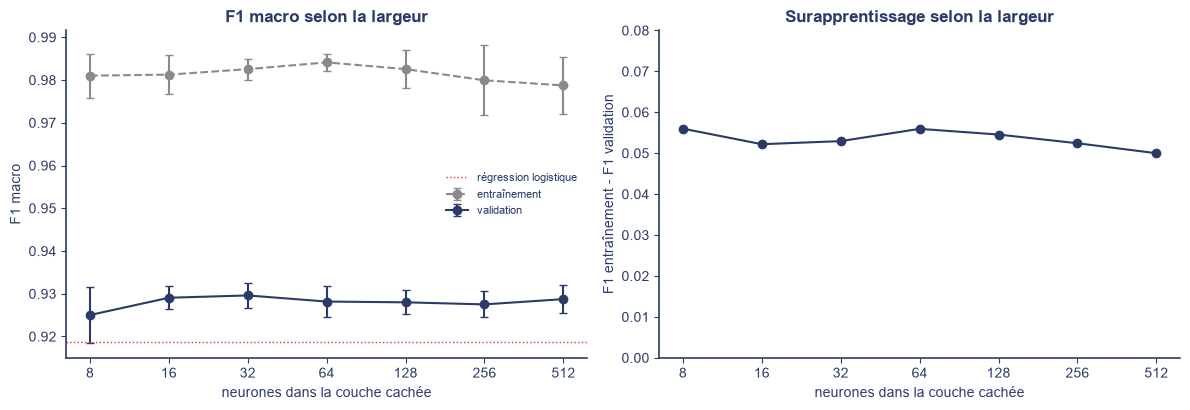

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
x = tab_largeur["largeur"]

ax[0].errorbar(x, tab_largeur["train_f1"], yerr=tab_largeur["train_f1_std"], color=GRIS_LIGNE, linestyle="--", marker="o", capsize=3, label="entraînement")
ax[0].errorbar(x, tab_largeur["val_f1"], yerr=tab_largeur["val_f1_std"], color=BLEU, marker="o", capsize=3, label="validation")
ax[0].axhline(ref_f1, color=ROUGE, linewidth=1, linestyle=":", label="régression logistique")
ax[0].set_xscale("log", base=2); ax[0].set_xticks(x); ax[0].set_xticklabels(x)
ax[0].set_xlabel("neurones dans la couche cachée"); ax[0].set_ylabel("F1 macro")
ax[0].set_title("F1 macro selon la largeur"); ax[0].legend(frameon=False, fontsize=8)

ax[1].plot(x, tab_largeur["ecart"], color=BLEU, marker="o")
ax[1].set_xscale("log", base=2); ax[1].set_xticks(x); ax[1].set_xticklabels(x)
ax[1].set_xlabel("neurones dans la couche cachée"); ax[1].set_ylabel("F1 entraînement - F1 validation")
ax[1].set_title("Surapprentissage selon la largeur")
ax[1].set_ylim(0, 0.08)
plt.tight_layout(); plt.show()

**rmqs: Impact de la largeur.**

- Avec ReLU, Adam (pas 0,001) et 5 graines, le F1 macro de validation reste compris entre 0,925 et 0,930 quand la couche cachée passe de 8 à 512 neurones (de 4 550 à 290 822 paramètres). Les écarts entre largeurs (au plus 0,005) sont du même ordre que les écarts-types entre graines (0,003 à 0,007) : on ne peut pas conclure qu'une largeur est meilleure qu'une autre. 
- Un réseau de 16 neurones (9 094 paramètres) obtient 0,9291 ± 0,0027, comme celui de 512 neurones (0,9287 ± 0,0033) avec trente fois moins de paramètres. Dès 16 neurones, le MLP dépasse la régression logistique (0,9187) d'environ 0,01, soit environ trois écarts-types.

- Le surapprentissage ne dépend pas non plus de la largeur : par exp dans le graphe 2 : 
    - pas de tendance nette : L’écart entre le F1 d’entraînement et celui de validation reste compris entre 0,050 et 0,056 pour toutes les largeurs, sans tendance croissante -> cause: early stopping


**conclusion** :La taille du réseau n’est pas le facteur limitant. Le plafond d’environ 0,93 vient de la généralisation à de nouveaux volontaires, pas d’un manque de capacité. Il y a donc peu de chances qu’ajouter des couches change beaucoup les choses : c’est la raison d’être de la régularisation .

## Profondeur 

Toutes les couches cachées ont **64 neurones**. On compare 1 à 4 couches cachées, et pour 2 et 3 couches plusieurs combinaisons d'activations. L'optimiseur est Adam avec un pas de 0,001 pour tous : ce pas appartient au plateau de la grille pour chaque activation, ce qui permet de comparer les architectures dans les mêmes conditions.

In [11]:
H = 64
archi = [
    # (nom, profondeur, activations)
    ("1 couche : relu",                     1, ["relu"]),
    ("2 couches : relu-relu",               2, ["relu", "relu"]),
    ("2 couches : tanh-tanh",               2, ["tanh", "tanh"]),
    ("2 couches : sigmoid-sigmoid",         2, ["sigmoid", "sigmoid"]),
    ("2 couches : relu-tanh",               2, ["relu", "tanh"]),
    ("2 couches : tanh-relu",               2, ["tanh", "relu"]),
    ("3 couches : relu-relu-relu",          3, ["relu", "relu", "relu"]),
    ("3 couches : tanh-tanh-tanh",          3, ["tanh", "tanh", "tanh"]),
    ("3 couches : relu-tanh-relu",          3, ["relu", "tanh", "relu"]),
    ("3 couches : tanh-relu-tanh",          3, ["tanh", "relu", "tanh"]),
    ("4 couches : relu x4",                 4, ["relu"] * 4),
    ("4 couches : tanh x4",                 4, ["tanh"] * 4),
]

lignes = []
for nom, prof, acts in archi:
    lignes.append(run_seeds(nom, (H,) * prof, acts))
    print(nom, "terminé")
tab_profondeur = pd.DataFrame(lignes)
afficher(tab_profondeur)

1 couche : relu terminé
2 couches : relu-relu terminé
2 couches : tanh-tanh terminé
2 couches : sigmoid-sigmoid terminé
2 couches : relu-tanh terminé
2 couches : tanh-relu terminé
3 couches : relu-relu-relu terminé
3 couches : tanh-tanh-tanh terminé
3 couches : relu-tanh-relu terminé
3 couches : tanh-relu-tanh terminé
4 couches : relu x4 terminé
4 couches : tanh x4 terminé


,configuration,paramètres,val F1,val acc,train F1,écart F1 (train - val),meilleure époque,temps (s)
0,1 couche : relu,36358,0.9282 ± 0.0037,0.9274 ± 0.0035,0.9841,0.0560,8.2,3.1
1,2 couches : relu-relu,40518,0.9252 ± 0.0056,0.9241 ± 0.0053,0.9820,0.0568,6.0,2.9
2,2 couches : tanh-tanh,40518,0.9101 ± 0.0099,0.9099 ± 0.0090,0.9748,0.0647,4.2,2.7
3,2 couches : sigmoid-sigmoid,40518,0.9092 ± 0.0137,0.9093 ± 0.0130,0.9817,0.0726,11.6,4.0
4,2 couches : relu-tanh,40518,0.9245 ± 0.0046,0.9233 ± 0.0044,0.9805,0.0560,5.4,2.8
5,2 couches : tanh-relu,40518,0.9159 ± 0.0070,0.9152 ± 0.0066,0.9720,0.0560,4.0,2.5
6,3 couches : relu-relu-relu,44678,0.9223 ± 0.0045,0.9201 ± 0.0054,0.9772,0.0549,5.2,2.8
7,3 couches : tanh-tanh-tanh,44678,0.9090 ± 0.0107,0.9084 ± 0.0099,0.9682,0.0592,4.2,2.6
8,3 couches : relu-tanh-relu,44678,0.9203 ± 0.0064,0.9183 ± 0.0067,0.9750,0.0547,4.0,2.6
9,3 couches : tanh-relu-tanh,44678,0.9158 ± 0.0043,0.9136 ± 0.0047,0.9739,0.0581,4.4,2.9


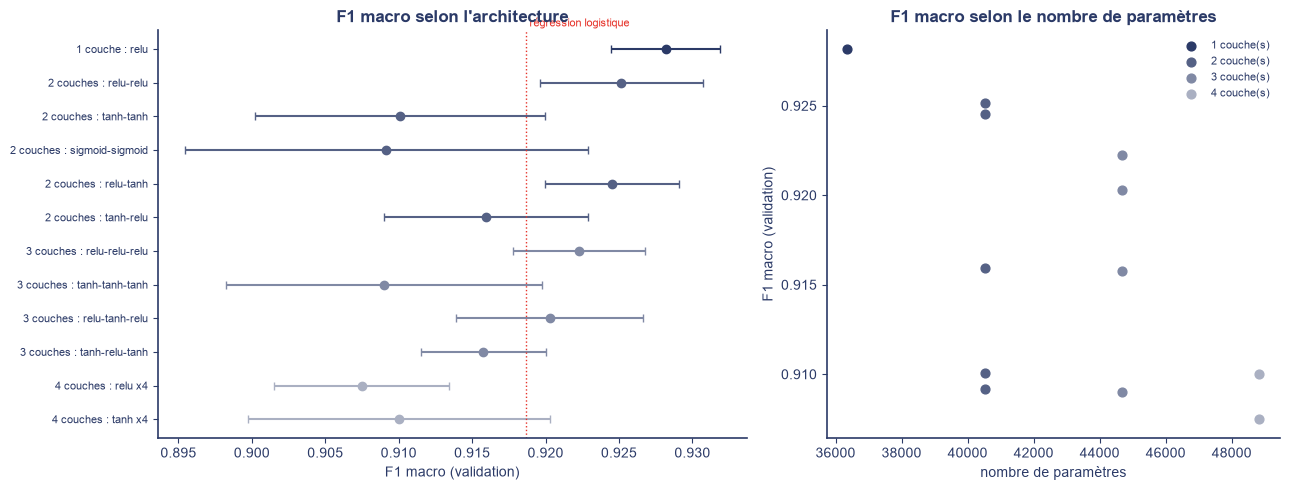

In [12]:
# F1 de validation par architecture (moyenne ± écart-type), colorée par profondeur
couleurs_prof = dict(zip([1, 2, 3, 4], teintes(4, 0.6)))
fig, ax = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.3, 1]})

y = np.arange(len(tab_profondeur))[::-1]
for yi, (_, r) in zip(y, tab_profondeur.iterrows()):
    ax[0].errorbar(r["val_f1"], yi, xerr=r["val_f1_std"], fmt="o", color=couleurs_prof[r["profondeur"]], capsize=3)
ax[0].axvline(ref_f1, color=ROUGE, linewidth=1, linestyle=":")
ax[0].text(ref_f1, len(y) - 0.4, " régression logistique", color=ROUGE, fontsize=8, va="bottom")
ax[0].set_yticks(y); ax[0].set_yticklabels(tab_profondeur["configuration"], fontsize=8)
ax[0].set_xlabel("F1 macro (validation)"); ax[0].set_title("F1 macro selon l'architecture")

for p in [1, 2, 3, 4]:
    d = tab_profondeur[tab_profondeur["profondeur"] == p]
    ax[1].scatter(d["params"], d["val_f1"], color=couleurs_prof[p], s=40, label=f"{p} couche(s)")
ax[1].set_xlabel("nombre de paramètres"); ax[1].set_ylabel("F1 macro (validation)")
ax[1].set_title("F1 macro selon le nombre de paramètres"); ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

**Question 3.2 — Impact de la profondeur et des combinaisons d'activations.**

Avec des couches de 64 neurones, Adam (pas 0,001) et 5 graines, ajouter des couches n'améliore pas le F1 macro de validation : avec ReLU, il passe de 0,9282 ± 0,0037 (1 couche) à 0,9252 ± 0,0056 (2 couches), 0,9223 ± 0,0045 (3 couches) et 0,9075 ± 0,0060 (4 couches), soit une baisse nette à 4 couches (plus de trois écarts-types) pour 34 % de paramètres en plus. Les réseaux à base de tanh ou de sigmoid sont moins bons (0,909 à 0,916) et nettement plus variables (écart-type jusqu'à 0,014), en dessous de la régression logistique (0,9187). L'ordre des activations compte : ReLU en première couche (relu-tanh, 0,9245) est plus favorable que tanh en première couche (tanh-relu, 0,9159). Le surapprentissage n'est pas réduit (écart train - validation de 0,055 à 0,073) et le temps d'entraînement reste comparable (2,5 à 4 s). Seule une couche ReLU dépasse la régression logistique au-delà de la variabilité entre graines. Le même pas d'apprentissage ayant été utilisé pour toutes les architectures, ce qui peut pénaliser les réseaux profonds à tanh ou sigmoid, cette conclusion reste à nuancer.

## 7. Synthèse : quelles configurations garder pour la suite ?

In [13]:
tous = pd.concat([tab_largeur.assign(partie="3.1 largeur"), tab_profondeur.assign(partie="3.2 profondeur")], ignore_index=True)
tous = tous.sort_values("val_f1", ascending=False).reset_index(drop=True)
meilleur = tous.iloc[0]
print(f"Meilleure configuration : {meilleur['configuration']} ({meilleur['partie']}) "
      f"| F1 = {meilleur['val_f1']:.4f} ± {meilleur['val_f1_std']:.4f} | {meilleur['params']} paramètres")

# Configurations indiscernables du meilleur : écart de F1 inférieur à l'écart-type du meilleur
proches = tous[(meilleur["val_f1"] - tous["val_f1"]) <= meilleur["val_f1_std"]]
print(f"\nConfigurations à moins d'un écart-type du meilleur ({len(proches)}) :")
display(proches[["partie", "configuration", "params", "val_f1", "val_f1_std", "ecart", "temps_s"]].round(4))

os.makedirs("../results", exist_ok=True)
tous.to_csv("../results/partie3_largeur_profondeur.csv", index=False)

Meilleure configuration : 32 neurones (3.1 largeur) | F1 = 0.9296 ± 0.0028 | 18182 paramètres

Configurations à moins d'un écart-type du meilleur (7) :


,partie,configuration,params,val_f1,val_f1_std,ecart,temps_s
0,3.1 largeur,32 neurones,18182,0.9296,0.0028,0.0530,3.0206
1,3.1 largeur,16 neurones,9094,0.9291,0.0027,0.0522,3.6020
2,3.1 largeur,512 neurones,290822,0.9287,0.0033,0.0500,3.9896
3,3.2 profondeur,1 couche : relu,36358,0.9282,0.0037,0.0560,3.1364
4,3.1 largeur,64 neurones,36358,0.9282,0.0037,0.0560,3.2017
5,3.1 largeur,128 neurones,72710,0.9280,0.0028,0.0546,3.0626
6,3.1 largeur,256 neurones,145414,0.9275,0.0031,0.0524,3.3575


Les largeurs de 16 à 512 neurones donnent des F1 de validation indiscernables (0,9275 à 0,9296, écart-types de 0,003). Le meilleur score (32 neurones, 0,9296 ± 0,0028) ne se distingue pas des autres au-delà de la variabilité entre graines : par parcimonie, nous retenons 32 et 64 neurones à une couche, ainsi qu’un réseau à deux couches (64, 64) pour tester l’effet de la régularisation sur un modèle plus profond.